# Part One : Understanding the hypothesis function

## 1- Mathematical Reminder

 for one feature we have the prediction : 
                     y = wx + b
 where: 
     w : the weight
     x : the feature
     b : the bias
     y = the prediction

## 2- Example of the hypothesis function

    let's take a dataset for y = 2x + 1

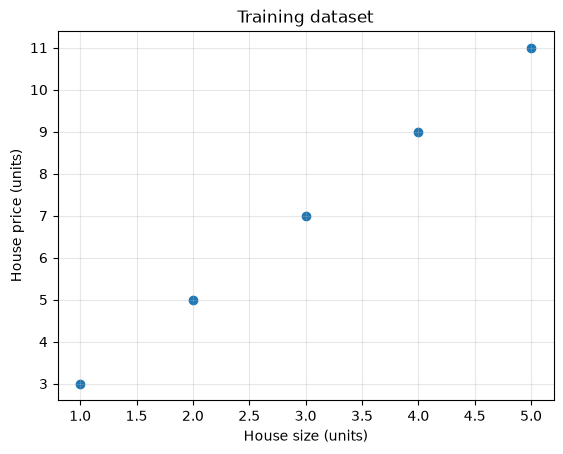

In [5]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([3, 5, 7, 9, 11], dtype=float)

plt.scatter(X, y)
plt.xlabel("House size (units)")
plt.ylabel("House price (units)")
plt.title("Training dataset")
plt.grid(alpha=0.3)
plt.show()

    suppose we don't know the value of w and b, we must figure out what are their values so we implement the hypothesis function

In [6]:
def predict(X, w, b):
    return w * X + b

w = 1     # we keep changing the values of w and b untill we find the right values
b = 0     #     for the actual y

y_pred = predict(X, w, b)

print("Predictions:", y_pred)
print("Actual:", y)

Predictions: [1. 2. 3. 4. 5.]
Actual: [ 3.  5.  7.  9. 11.]


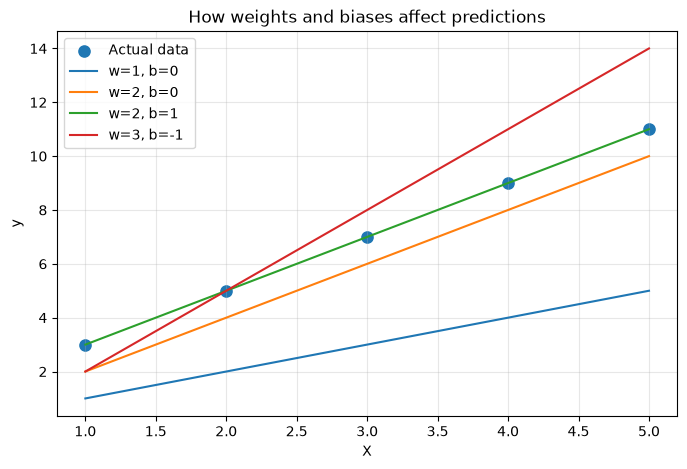

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(X, y, label="Actual data", s=65)

for w, b in [(1, 0), (2, 0), (2, 1), (3, -1)]:     # choosing random w and b untill reach the right prediction
    plt.plot(X, predict(X, w, b), label=f"w={w}, b={b}")

plt.xlabel("X")
plt.ylabel("y")
plt.title("How weights and biases affect predictions")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Part Two : Understanding the cost function

## Mean Squared Error

    The MSE is defined by: 
                MSE = 1/m * (sum((actual_y - pred_y)^2))
    Where: 
        m: the number of values

## Implementing the cost function

In [13]:
def compute_cost(X, y, w, b):
    m = len(X)

    predictions = predict(X, w, b)
    errors = predictions - y

    cost = np.sum(errors ** 2) / (2 * m)

    return cost

In [6]:
#TEST
print("Cost (w=1, b=0):", compute_cost(X, y, 1, 0))
print("Cost (w=2, b=0):", compute_cost(X, y, 2, 0))
print("Cost (w=2, b=1):", compute_cost(X, y, 2, 1))

Cost (w=1, b=0): 9.0
Cost (w=2, b=0): 0.5
Cost (w=2, b=1): 0.0


## Cost function visualization

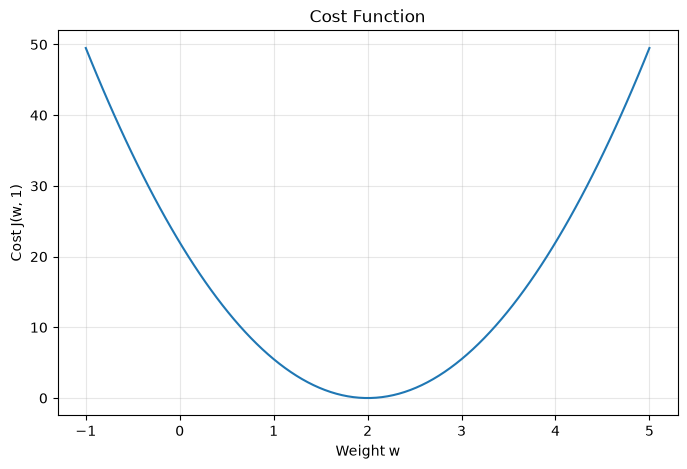

In [14]:
w_values = np.linspace(-1, 5, 100)

costs = [
    compute_cost(X, y, w, 1) # Fixing b at the moment
    for w in w_values        # the minimum is the best option
]

plt.figure(figsize=(8, 5))

plt.plot(w_values, costs)
plt.xlabel("Weight w")
plt.ylabel("Cost J(w, 1)")
plt.title("Cost Function")
plt.grid(alpha=0.3)
plt.show()

# Part Three : How do we find the optimal parameters

## 1- Mathematical derivation

    we want to minimize the J(w,b) = 1/2 * MSE
    so the derivative resp to w = 0, so as resp for b
    we obtain after solving the equation:
                    w = (sum(xi -x)(yi-y))/sum((xi-x)^2)
                and b = y- wx

## 2- Implement the analytical solution

In [15]:
def fit_linear_regression(X, y):
    x_mean = np.mean(X)
    y_mean = np.mean(y)

    numerator = np.sum(
        (X - x_mean) * (y - y_mean)
    )

    denominator = np.sum(
        (X - x_mean) ** 2
    )

    if np.isclose(denominator, 0):
        raise ValueError("X must contain varying values")

    w = numerator / denominator
    b = y_mean - w * x_mean

    return w, b

In [16]:
w_opt, b_opt = fit_linear_regression(X, y) #Training

print("Optimal weight:", w_opt)
print("Optimal bias:", b_opt)
print("Final cost:", compute_cost(X, y, w_opt, b_opt))

Optimal weight: 2.0
Optimal bias: 1.0
Final cost: 0.0


# Part Four : Visualizing the trained model

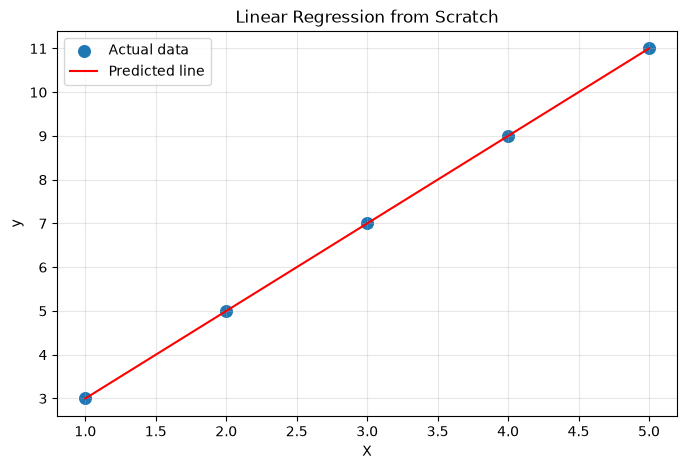

In [17]:
y_pred = predict(X, w_opt, b_opt)

plt.figure(figsize=(8, 5))

plt.scatter(X, y, label="Actual data", s=70)
plt.plot(X, y_pred, color="red", label="Predicted line")

plt.xlabel("X")
plt.ylabel("y")
plt.title("Linear Regression from Scratch")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [18]:
new_x = 6

new_prediction = predict(new_x, w_opt, b_opt) #Now prediting Unseen Values

print("Prediction for x=6:", new_prediction)

Prediction for x=6: 13.0


# Part five : Apply linear regression to housing data

    We're going to use the dataset of the first Lab

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

housing = pd.read_csv("../01-python-ml-tools/housing_lab01.csv")

X = housing["area"].to_numpy(dtype=float)
y = housing["price"].to_numpy(dtype=float)

w, b = fit_linear_regression(X, y)

print("Learned weight:", w)
print("Learned bias:", b)
print("Training cost:", compute_cost(X, y, w, b))

Learned weight: 2.5082108765471496
Learned bias: 34.55533077152285
Training cost: 540.4553545170711


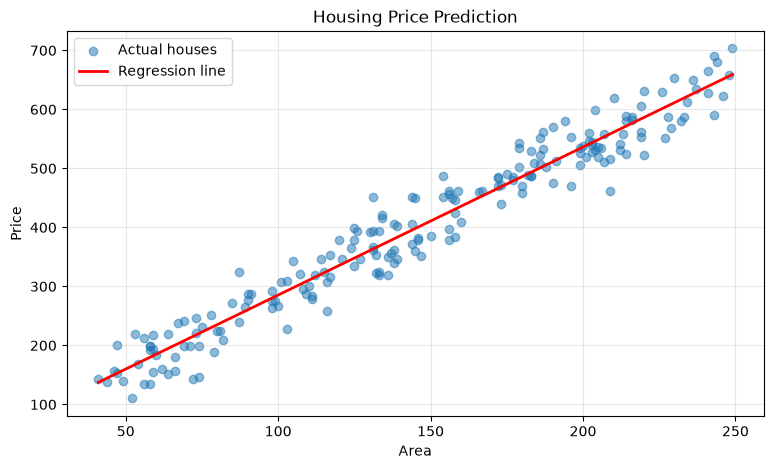

In [20]:
y_pred = predict(X, w, b)

order = np.argsort(X)

plt.figure(figsize=(9, 5))

plt.scatter(X, y, alpha=0.5, label="Actual houses")

plt.plot(
    X[order],
    y_pred[order],
    color="red",
    linewidth=2,
    label="Regression line"
)

plt.xlabel("Area")
plt.ylabel("Price")
plt.title("Housing Price Prediction")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Understanding the residuals

    A residual is the difference between the observed value and the prediction:
                        e = yi - y_pred

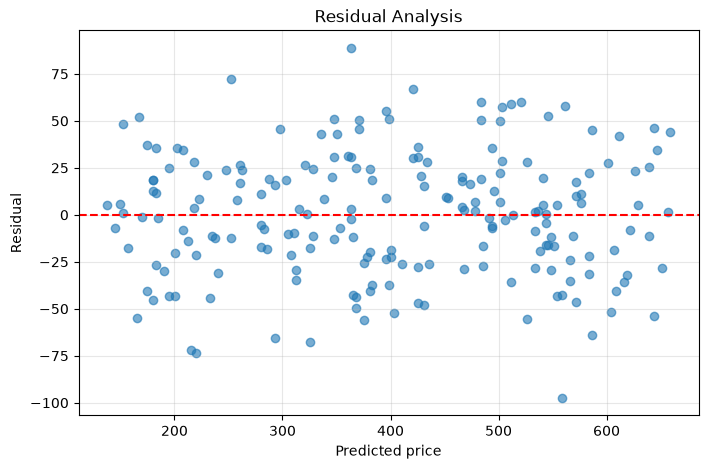

In [21]:
residuals = y - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted price")
plt.ylabel("Residual")
plt.title("Residual Analysis")
plt.grid(alpha=0.3)
plt.show()

# Part Six : Lab 02 Challenges

## 1- Implementing MAE and RMSE

In [22]:
def compute_MAE(X,y,w,b) :
    m = len(X)
    prediction = predict(X,w,b)
    MAE = (1/m) * (np.sum(abs(prediction - y)))
    return MAE

In [23]:
def compute_RMSE(X,y,w,b):
    m = len(X)
    prediction = predict(X,w,b)
    error = prediction - y
    RMSE = np.sqrt((1/m)* np.sum(error**2))
    return RMSE

In [24]:
# Test
print("Cost MSE (w=1, b=0):", compute_cost(X, y, 1, 0))
print("Cost MAE (w=1, b=0):", compute_MAE(X, y, 1, 0))
print("Cost RMSE (w=1, b=0):", compute_RMSE(X, y, 1, 0))


Cost MSE (w=1, b=0): 36906.67882900073
Cost MAE (w=1, b=0): 255.3347799348774
Cost RMSE (w=1, b=0): 271.6861381410569


## 2- How Outliars affect the Linear Regression

Original model: 2.5082108765471496 34.55533077152285
With outlier: 2.4585965804145453 45.36201116486251


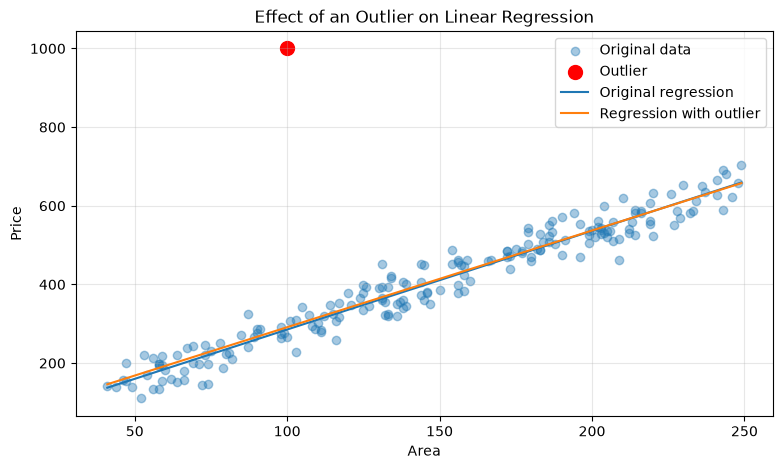

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

housing = pd.read_csv("../01-python-ml-tools/housing_lab01.csv")

X = housing["area"].to_numpy(dtype=float)
y = housing["price"].to_numpy(dtype=float)

# Original model
w1, b1 = fit_linear_regression(X, y)

# Add an extreme outlier
X_outlier = np.append(X, 100)
y_outlier = np.append(y, 1000)

# Retrain
w2, b2 = fit_linear_regression(X_outlier, y_outlier)

print("Original model:", w1, b1)
print("With outlier:", w2, b2)

x_line = np.linspace(X.min(), X.max(), 100)

plt.figure(figsize=(9, 5))
plt.scatter(X, y, alpha=0.4, label="Original data")
plt.scatter([100], [1000], color="red", s=100, label="Outlier")

plt.plot(x_line, w1*x_line+b1, label="Original regression")
plt.plot(x_line, w2*x_line+b2, label="Regression with outlier")

plt.xlabel("Area")
plt.ylabel("Price")
plt.title("Effect of an Outlier on Linear Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 3- Implementing R**2

In [26]:
def r2_score_scratch(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    if len(y_true) < 2:
        raise ValueError("R² requires at least two samples")

    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)

    if np.isclose(ss_tot, 0):
        return 1.0 if np.isclose(ss_res, 0) else 0.0

    return 1 - ss_res / ss_tot

In [28]:
from sklearn.metrics import r2_score

y_true = np.array([3, 5, 7, 9, 11])
y_pred = np.array([3, 5.5, 6.5, 9, 10])

print("Our R²:", r2_score_scratch(y_true, y_pred))
print("Sklearn R²:", r2_score(y_true, y_pred))

Our R²: 0.9625
Sklearn R²: 0.9625


## 4- Complete Linear Regression

In [29]:
import numpy as np

class LinearRegressionScratch:

    def __init__(self):
        self.w = None
        self.b = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float).reshape(-1)
        y = np.asarray(y, dtype=float).reshape(-1)

        if len(X) != len(y):
            raise ValueError("X and y must have equal lengths")

        if len(X) == 0:
            raise ValueError("Dataset cannot be empty")

        x_mean = np.mean(X)
        y_mean = np.mean(y)

        numerator = np.sum(
            (X - x_mean) * (y - y_mean)
        )

        denominator = np.sum((X - x_mean) ** 2)

        if np.isclose(denominator, 0):
            raise ValueError("X must contain varying values")

        self.w = numerator / denominator
        self.b = y_mean - self.w * x_mean

        return self

    def predict(self, X):
        if self.w is None:
            raise RuntimeError("Fit the model before prediction")

        X = np.asarray(X, dtype=float)
        return self.w * X + self.b

    def score(self, X, y):
        predictions = self.predict(X)
        return r2_score_scratch(
            np.asarray(y, dtype=float).reshape(-1),
            np.asarray(predictions).reshape(-1)
        )

In [30]:
model = LinearRegressionScratch()

X_test = np.array([1, 2, 3, 4, 5], dtype=float)
y_test = np.array([3, 5, 7, 9, 11], dtype=float)

model.fit(X_test, y_test)

assert np.isclose(model.w, 2)
assert np.isclose(model.b, 1)
assert np.isclose(model.predict(np.array([6]))[0], 13)
assert np.isclose(model.score(X_test, y_test), 1)

print("All tests passed!")

All tests passed!


    Also notice that fit() returns self. This lets us write:

In [31]:
model = LinearRegressionScratch().fit(X_test, y_test)